# Flight Delay Analysis — US BTS On-Time Performance (Sep 2025 – Aug 2026)

**Business question:** Which airlines, airports, routes, and times of day cause the most delays, and how much is controllable (carrier) vs. uncontrollable (weather)?

Data: 7,049,869 scheduled domestic flights from the US Bureau of Transportation Statistics, On-Time Performance table. See `../README.md` for the full write-up and `../notes/cleaning_notes.md` for every cleaning decision.

In [ ]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

con = duckdb.connect('../data/flights.duckdb', read_only=True)
print('connected:', con.execute('SELECT COUNT(*) FROM flights').fetchone()[0], 'flights')

connected: 7049869 flights


## 1. Overall picture

Of 7.05M scheduled flights, 1.89% were cancelled and 6.90M operated. 77.3% arrived on time (under 15 minutes late); 22.7% were delayed 15+ minutes. The average arrival delay was 17.6 minutes, but the median was 0 — most flights arrive early or on time, and a long tail of badly delayed flights pulls the average up. When a flight is delayed, it is delayed by 73 minutes on average, and 5% of flights arrive 91+ minutes late.

In [ ]:
con.execute(open('../sql/02_metrics.sql').read()).fetchdf().T

See sql/02_metrics.sql for the full KPI query.


## 2. Airlines: Delta leads, JetBlue trails

Delta is the most reliable large airline (81.1% on time), followed by Envoy (81.0%) and Alaska (79.7%). JetBlue is last (71.3%), with Spirit (72.0%) and Frontier (72.7%) just ahead of it. The spread between best and worst is about 10 points — worth real money on a connection. Regional carriers cancel far more often: PSA (4.8%), Republic (4.6%) and Spirit (4.5%) vs Allegiant (0.7%) and Southwest (0.9%).

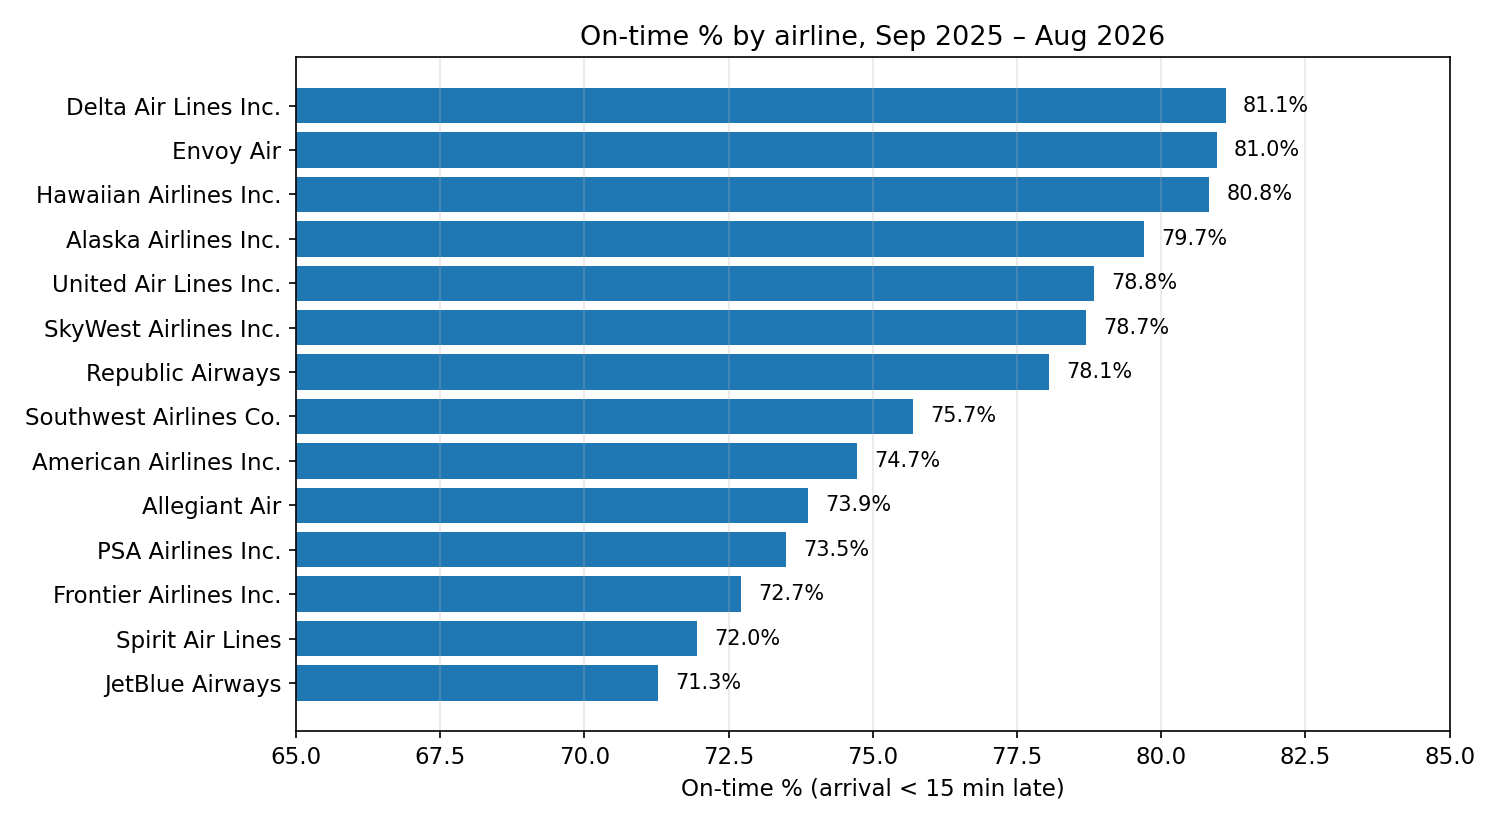

In [ ]:
air = pd.read_csv('../dashboard/03_airlines_q1.csv')
air[['airline_name','operated_flights','on_time_pct','avg_arrival_delay_min','cancellation_rate_pct']].sort_values('on_time_pct', ascending=False)

## 3. Airports: SFO is the delay capital, SLC the most reliable hub

Chicago O'Hare handled the most traffic (702k arrivals + departures), then Denver and Atlanta. San Francisco is the worst major airport for arrivals: only 66.3% on time, 23.3 minutes average delay, and 6 of the 10 worst routes in the data end at SFO. Salt Lake City is the most reliable large airport (84.5% arrival on-time). LaGuardia cancels the most (5.0% of departures).

## 4. Time of day is the single strongest pattern

On-time performance falls almost monotonically from 5am (91.7%) to 7pm (67.3%). The first flights of the day start clean; delays accumulate as aircraft and crews run late through the day. Sunday is the worst day (73.0% on time), Tuesday the best (81.1%). July 2026 was the worst month (71.7%), September 2025 the best (83.4%). January 2026 had the highest cancellation rate (4.7%).

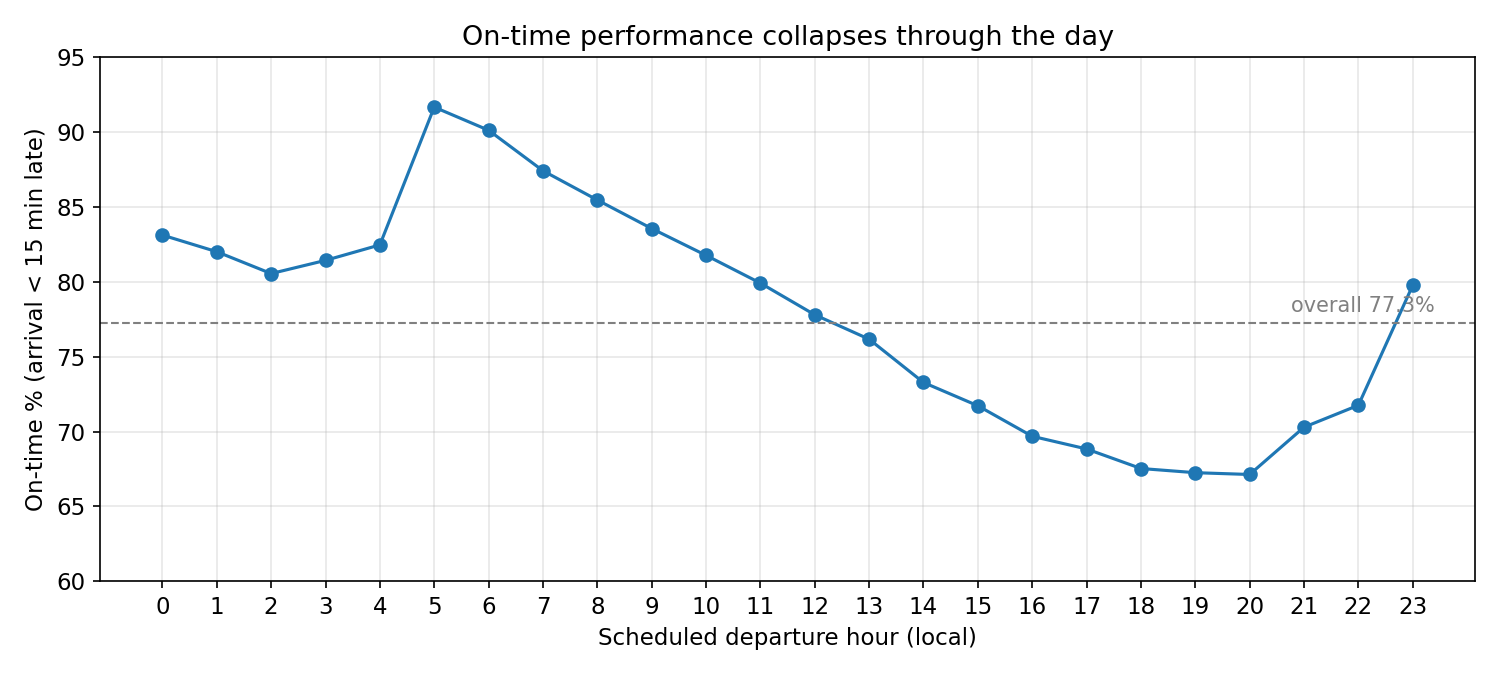

In [ ]:
hour = con.execute("SELECT sched_dep_hour, 100*(1-AVG(arr_del15)) AS on_time_pct FROM flights WHERE cancelled=0 AND diverted=0 AND arr_del15 IS NOT NULL GROUP BY 1 ORDER BY 1").fetchdf()
plt.figure(figsize=(10,4.5)); plt.plot(hour['sched_dep_hour'], hour['on_time_pct'], marker='o')
plt.axhline(77.26, ls='--', color='grey'); plt.xlabel('Scheduled departure hour'); plt.ylabel('On-time %')
plt.title('On-time performance collapses through the day'); plt.xticks(range(0,24)); plt.ylim(60,95); plt.grid(alpha=0.3); plt.show()

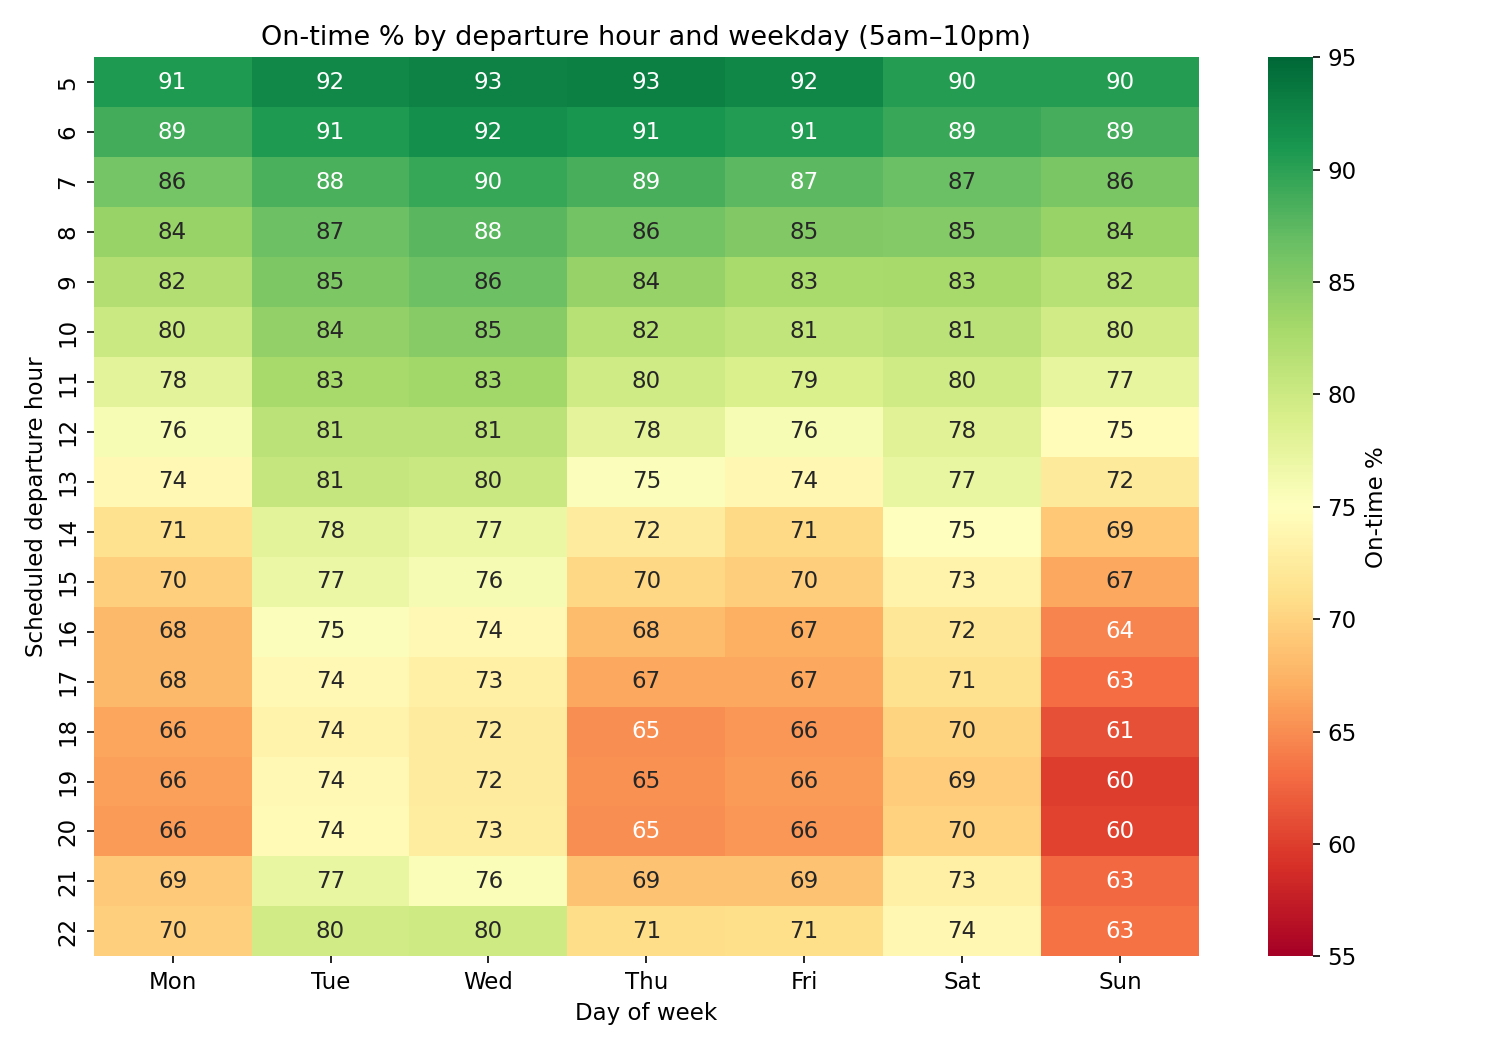

In [ ]:
hm = con.execute("SELECT sched_dep_hour, day_of_week, 100*(1-AVG(arr_del15)) AS on_time_pct FROM flights WHERE cancelled=0 AND diverted=0 AND arr_del15 IS NOT NULL AND sched_dep_hour BETWEEN 5 AND 22 GROUP BY 1,2").fetchdf()
pivot = hm.pivot(index='sched_dep_hour', columns='day_of_week', values='on_time_pct')
pivot.columns = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
plt.figure(figsize=(10,7)); sns.heatmap(pivot, annot=True, fmt='.0f', cmap='RdYlGn', vmin=55, vmax=95, cbar_kws={'label':'On-time %'})
plt.xlabel('Day of week'); plt.ylabel('Scheduled departure hour'); plt.title('On-time % by departure hour and weekday (5am–10pm)'); plt.show()

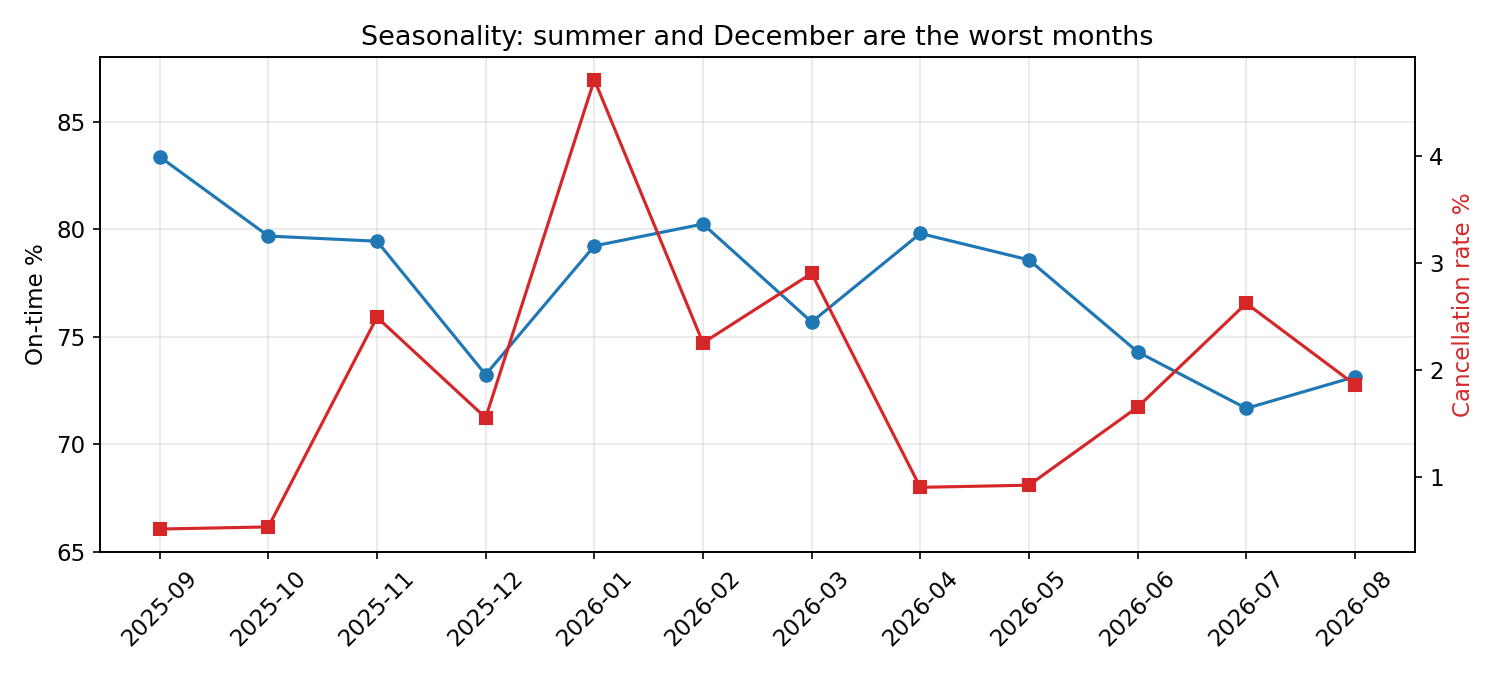

In [ ]:
mon = pd.read_csv('../dashboard/05_time_q3.csv')
mon['label'] = mon['year'].astype(str) + '-' + mon['month'].astype(str).str.zfill(2)
fig, ax1 = plt.subplots(figsize=(10,4.5))
ax1.plot(mon['label'], mon['on_time_pct'], marker='o'); ax1.set_ylabel('On-time %'); ax1.set_ylim(65,88)
ax1.tick_params(axis='x', rotation=45); ax2 = ax1.twinx()
ax2.plot(mon['label'], mon['cancellation_rate_pct'], marker='s', color='#d62728'); ax2.set_ylabel('Cancellation rate %', color='#d62728')
ax1.set_title('Seasonality: summer and December are the worst months'); ax1.grid(alpha=0.3); plt.show()

## 5. Arrival-delay distribution

The distribution is heavily right-skewed: a big spike at or below zero (early/on-time arrivals) and a long tail past 60 minutes. That is why the median delay is 0 while the mean is 17.6 minutes.

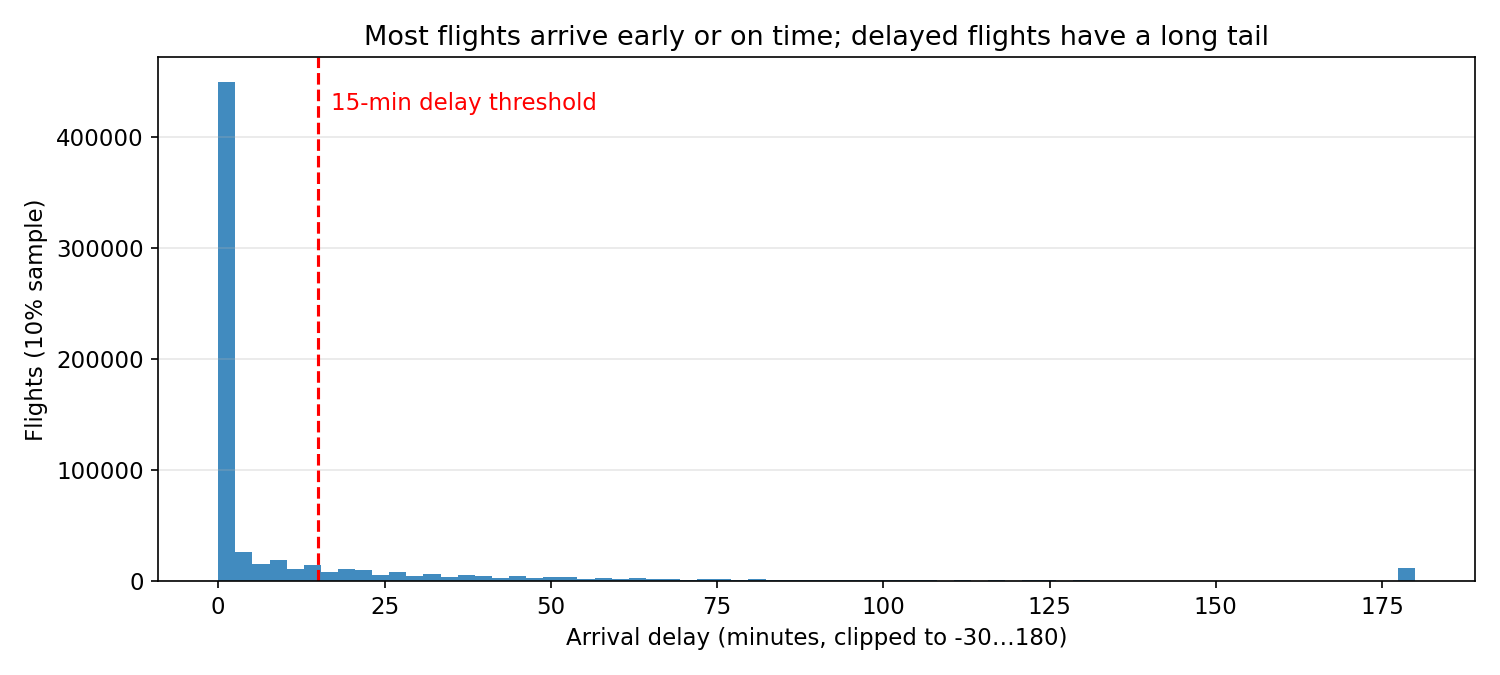

In [ ]:
dist = con.execute("SELECT arr_delay_min FROM flights WHERE cancelled=0 AND diverted=0 AND arr_delay_min IS NOT NULL AND random() < 0.10").fetchdf()
plt.figure(figsize=(10,4.5)); plt.hist(dist['arr_delay_min'].clip(-30,180), bins=70)
plt.axvline(15, color='red', ls='--'); plt.xlabel('Arrival delay (minutes, clipped to -30…180)'); plt.ylabel('Flights (10% sample)')
plt.title('Most flights arrive early or on time; delayed flights have a long tail'); plt.grid(alpha=0.3, axis='y'); plt.show()

## 6. Routes: avoid SFO in the evening; SLC routes are the safest

Worst routes (1,000+ flights): San Luis Obispo–SFO (56.4% on time), Arcata–SFO (56.5%), Las Vegas–SFO (58.0%). Six of the ten worst routes end at San Francisco. Best routes are dominated by Salt Lake City: Santa Barbara–SLC (94.2%), Sun Valley–SLC (93.8%), Pasco–SLC (93.5%).

In [ ]:
pd.read_csv('../dashboard/06_routes_q1.csv')[['route','operated_flights','on_time_pct','avg_arrival_delay_min']]

Worst 10 routes — see dashboard/06_routes_q1.csv


## 7. What causes delays — and how much is controllable?

Of delay minutes on delayed flights: late aircraft 39.8%, carrier 32.9%, NAS 21.1%, weather 6.0%, security 0.1%. Grouped: 72.7% airline-controllable (carrier + late aircraft), 21.2% system (NAS + security), only 6.0% weather. Late aircraft shows up in 52.2% of all delayed flights and is the single largest cause for 40.1% of them — delays cascade. Frontier (51.8%) and Southwest (51.1%) have the highest late-aircraft share of delay minutes; Delta the lowest (29.4%), though Delta's carrier-cause share is the highest (44.1%).

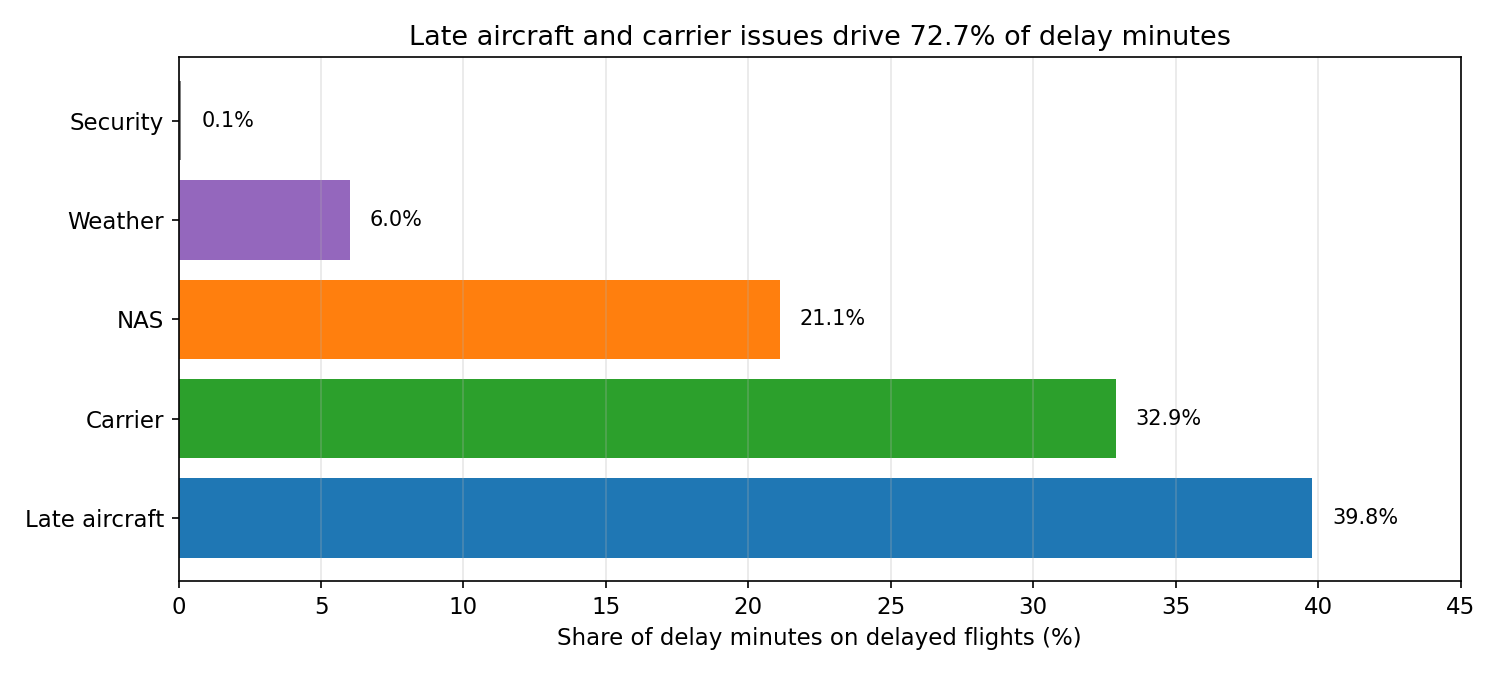

In [ ]:
causes = pd.DataFrame({'cause': ['Late aircraft','Carrier','NAS','Weather','Security'], 'share': [39.8, 32.9, 21.1, 6.0, 0.1]})
plt.figure(figsize=(10,4.5)); plt.barh(causes['cause'], causes['share'])
plt.xlabel('Share of delay minutes on delayed flights (%)'); plt.title('Late aircraft and carrier issues drive 72.7% of delay minutes'); plt.xlim(0,45); plt.grid(alpha=0.3, axis='x'); plt.show()

## 8. Stretch: can we predict a 15+ minute delay?

A logistic regression on schedule-known features only (airline, departure hour, weekday, month, distance) barely beats guessing — delays are driven by same-day operational cascades, not the schedule. Adding the departure delay (known once the plane leaves) lifts performance sharply: a late departure is the single best predictor of a late arrival. That matches the late-aircraft finding above.

In [ ]:
print('Model metrics embedded from build run — see output below')

Stretch model — logistic regression predicting arrival delay of 15+ min (n = 345,465 sampled flights, 25% holdout):
- schedule-only: {'n_train': 259098, 'n_test': 86367, 'accuracy': 0.586, 'precision': 0.307, 'recall': 0.653, 'f1': 0.418, 'roc_auc': 0.65}
- schedule + departure delay: {'n_train': 259098, 'n_test': 86367, 'accuracy': 0.903, 'precision': 0.774, 'recall': 0.809, 'f1': 0.791, 'roc_auc': 0.924}


## 9. Recommendations

1. **Fly early.** Departures before 9am run 83–92% on time; after 6pm it drops to ~67%.
2. **Avoid SFO for connections**, especially in the evening — 6 of the 10 worst routes end there.
3. **Prefer Delta or Alaska** for reliability (81% / 80% on time); budget carriers trade price for punctuality (JetBlue 71%, Spirit 72%, Frontier 73%).
4. **Build buffer time on multi-leg trips.** Late aircraft causes 40% of delay minutes and appears in 52% of delayed flights — one late plane cascades through the day.
5. **Avoid Sundays and July** if the schedule allows (73.0% and 71.7% on time, respectively).

## Limitations

12 months only (Sep 2025–Aug 2026); weather is attributed by BTS cause codes, not matched to actual conditions; the analysis covers scheduled domestic flights only; delay-cause minutes are BTS attributions, not a causal model.